<a href="https://colab.research.google.com/github/PedroNishimura/feedback_model/blob/main/feedbackModel_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificador de sentimento (versão melhorada)

Notebook de estudo: classifica avaliações de produtos em português como **positivas** ou **negativas**.

## O que mudou em relação à versão original

| # | Problema na versão original | Correção aqui |
|---|---|---|
| 1 | Textos duplicados caíam no treino **e** no teste (vazamento, acurácia inflada) | Deduplicação **antes** do split |
| 2 | Mesmo texto com rótulos diferentes (ruído) | Detectamos e removemos conflitos |
| 3 | Sem baseline | `DummyClassifier` como piso de comparação |
| 4 | `StandardScaler` após TF-IDF sem justificativa | Comparamos **com e sem** scaler usando validação cruzada |
| 5 | Stop words curtas, sem cuidado com negações | Lista que **preserva** "não", "nunca", "sem"... |
| 6 | Só Regressão Logística | Comparação com LinearSVC e Naive Bayes |
| 7 | Avaliação só com acurácia | Acurácia, F1, matriz de confusão **e análise de erros** |
| 8 | Modelo era uma "caixa-preta" | Inspeção dos **coeficientes** (palavras que mais pesam) |
| 9 | Predição só devolvia a classe | Devolvemos também a **probabilidade** |

## 1. Importações

In [1]:
import re
import unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Carregamento e exploração

Além de formato e nulos, agora medimos **duplicatas** e o **balanceamento** das classes.

In [3]:
csv_path = "/content/dataset.csv"   # ajuste se rodar fora do Colab
df = pd.read_csv(csv_path)

print("Formato:", df.shape)
print("\nNulos por coluna:")
print(df.isnull().sum())
print("\nTextos duplicados (exatos):", df["texto_review"].duplicated().sum())
df.head()

Formato: (500, 3)

Nulos por coluna:
review_id        0
texto_review    12
sentimento       0
dtype: int64

Textos duplicados (exatos): 216


,review_id,texto_review,sentimento
0,1,Estou muito feliz com a compra. O cadeira game...,positivo
1,2,NaN,negativo
2,3,Não recomendo. A entrega foi lenta e o celular...,negativo
3,4,O monitor é decepcionante. O suporte ao client...,positivo
4,5,É UM LIVRO OK PELO PRÇEO QUE PAGUEI.,negativo


sentimento
positivo    0.522
negativo    0.478
Name: proportion, dtype: float64


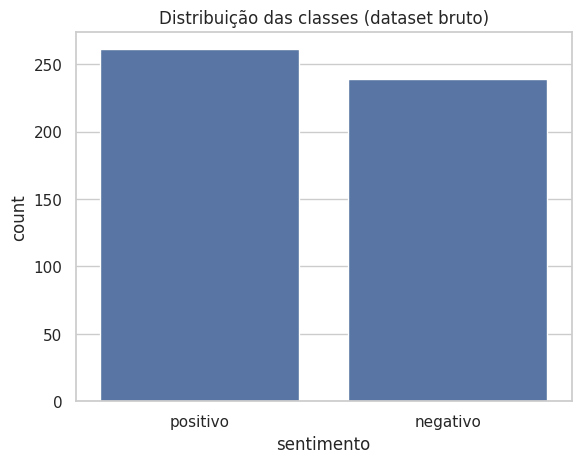

In [4]:
print(df["sentimento"].value_counts(normalize=True).round(3))
sns.countplot(x="sentimento", data=df)
plt.title("Distribuição das classes (dataset bruto)")
plt.show()

## 3. Limpeza

### 3.1 Função de normalização
Minúsculas, sem acentos, só letras e espaços. A lógica é a mesma da versão original.

In [5]:
def clear_text(text):
    if not isinstance(text, str):
        return ""
    # NFKD separa letra + acento; descartamos os acentos (categoria 'Mn')
    sem_acento = "".join(c for c in unicodedata.normalize("NFKD", text)
                         if unicodedata.category(c) != "Mn")
    texto = sem_acento.lower()
    texto = re.sub(r"[^a-z\s]", "", texto)   # remove pontuação e números
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

df = df.dropna(subset=["texto_review"]).copy()
df["clear_text"] = df["texto_review"].apply(clear_text)
df = df[df["clear_text"] != ""]
print("Linhas após remover nulos/vazios:", len(df))

Linhas após remover nulos/vazios: 488


### 3.2 Conflitos de rótulo e duplicatas

Dois problemas diferentes:

- **Duplicata consistente**: mesmo texto, mesmo rótulo. Se ficar no dataset, pode cair em treino e teste ao mesmo tempo e inflar a métrica.
- **Conflito**: mesmo texto, rótulos diferentes. É ruído puro, nenhum modelo acerta os dois.

Os conflitos são removidos por completo; depois mantemos uma única cópia de cada texto.

In [6]:
# Quantos rótulos distintos cada texto tem?
rotulos_por_texto = df.groupby("clear_text")["sentimento"].nunique()
textos_conflitantes = rotulos_por_texto[rotulos_por_texto > 1].index

print("Textos com rótulos conflitantes:", len(textos_conflitantes))
display(df[df["clear_text"].isin(textos_conflitantes)]
        .sort_values("clear_text")[["texto_review", "sentimento"]].head(10))

Textos com rótulos conflitantes: 37


,texto_review,sentimento
279,A cor do fone de ouvido é um pouco diferente d...,positivo
194,A cor do fone de ouvido é um pouco diferente d...,positivo
429,A cor do fone de ouvido é um pouco diferente d...,negativo
128,A cor do fone de ouvido é um pouco diferente d...,positivo
57,A cor do monitor é um pouco diferente do que e...,negativo
215,A cor do monitor é um pouco diferente do que e...,negativo
352,A cor do monitor é um pouco diferente do que e...,positivo
445,A cor do mouse é um pouco diferente do que eu ...,negativo
119,A cor do mouse é um pouco diferente do que eu ...,positivo
187,A embalagem do celular chegou um pouco amassad...,positivo


In [7]:
antes = len(df)
df = df[~df["clear_text"].isin(textos_conflitantes)]     # remove conflitos
df = df.drop_duplicates(subset="clear_text")             # 1 cópia de cada texto
print(f"{antes} -> {len(df)} linhas ({antes - len(df)} removidas)")
print(df["sentimento"].value_counts())

488 -> 229 linhas (259 removidas)
sentimento
positivo    124
negativo    105
Name: count, dtype: int64


> **Atenção:** o dataset agora é bem menor. Isso é a realidade honesta dos dados: antes, boa parte das linhas era repetição.
> Com poucas amostras, **qualquer métrica tem muita variância**, por isso usaremos validação cruzada repetida mais adiante.

### 3.3 Codificação do alvo

In [8]:
df["label"] = df["sentimento"].map({"negativo": 0, "positivo": 1})
X = df["clear_text"]
y = df["label"]

## 4. Separação treino/teste

Agora **sem vazamento por duplicatas**. `stratify=y` mantém a proporção das classes.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Treino:", len(X_train), "| Teste:", len(X_test))

Treino: 171 | Teste: 58


## 5. Stop words que respeitam a negação

Em análise de sentimento, **"não recomendo"** e **"recomendo"** têm sentidos opostos.
Por isso a lista abaixo remove só palavras vazias, e **mantém** negações e intensificadores.

Como o texto já está sem acentos, a lista também precisa estar sem acentos.

In [10]:
STOP_WORDS_PT = [
    "de", "a", "o", "as", "os", "que", "e", "do", "da", "dos", "das", "em",
    "um", "uma", "uns", "umas", "para", "pra", "por", "com", "no", "na",
    "nos", "nas", "ao", "aos", "se", "foi", "ser", "esta", "esse", "essa",
    "isso", "este", "pelo", "pela", "ou", "como", "ja", "so",
]

## 6. Baseline

Antes de modelar, pergunte: **"quanto um modelo sem nenhuma inteligência acertaria?"**
Se o modelo real não bate esse piso, ele não aprendeu nada útil.

In [11]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline (sempre prevê a classe majoritária):",
      round(accuracy_score(y_test, dummy.predict(X_test)), 3))

Baseline (sempre prevê a classe majoritária): 0.534


## 7. Comparando arquiteturas com validação cruzada

Em vez de confiar em um único split, usamos **validação cruzada repetida** (5 folds × 3 repetições = 15 avaliações por modelo).
Todas as comparações usam **apenas o conjunto de treino**; o teste continua intocado até o final.

Perguntas que esta etapa responde:
1. O `StandardScaler` realmente ajuda? (hipótese: não, o TF-IDF já é normalizado)
2. Bigramas (`ngram_range=(1,2)`) ajudam a capturar negações?
3. Qual família de modelo funciona melhor?

In [12]:
def tfidf(ngram=(1, 1)):
    return TfidfVectorizer(stop_words=STOP_WORDS_PT, ngram_range=ngram,
                           sublinear_tf=True)

candidatos = {
    "LogReg (original, com scaler)": Pipeline([
        ("tfidf", tfidf()),
        ("scaler", StandardScaler(with_mean=False)),
        ("clf", LogisticRegression(solver="liblinear", random_state=RANDOM_STATE)),
    ]),
    "LogReg (sem scaler)": Pipeline([
        ("tfidf", tfidf()),
        ("clf", LogisticRegression(solver="liblinear", random_state=RANDOM_STATE)),
    ]),
    "LogReg + bigramas": Pipeline([
        ("tfidf", tfidf((1, 2))),
        ("clf", LogisticRegression(solver="liblinear", random_state=RANDOM_STATE)),
    ]),
    "LinearSVC": Pipeline([
        ("tfidf", tfidf((1, 2))),
        ("clf", LinearSVC(random_state=RANDOM_STATE)),
    ]),
    "Naive Bayes": Pipeline([
        ("tfidf", tfidf((1, 2))),
        ("clf", MultinomialNB()),
    ]),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

resultados = []
for nome, pipe in candidatos.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                             scoring="f1_macro", n_jobs=-1)
    resultados.append({"modelo": nome,
                       "f1_macro (média)": scores.mean(),
                       "desvio": scores.std()})

df_res = pd.DataFrame(resultados).sort_values("f1_macro (média)", ascending=False)
df_res.round(3)

,modelo,f1_macro (média),desvio
0,"LogReg (original, com scaler)",0.885,0.039
3,LinearSVC,0.885,0.032
2,LogReg + bigramas,0.880,0.038
1,LogReg (sem scaler),0.878,0.040
4,Naive Bayes,0.876,0.039


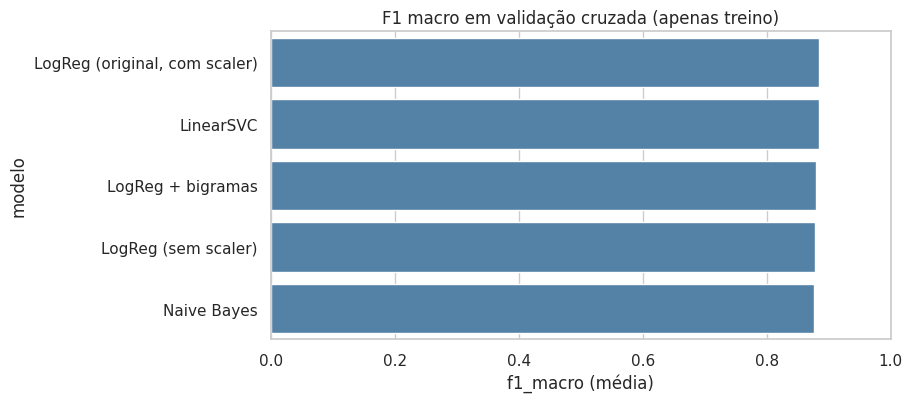

In [13]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df_res, y="modelo", x="f1_macro (média)", color="steelblue")
plt.xlim(0, 1)
plt.title("F1 macro em validação cruzada (apenas treino)")
plt.show()

**Como ler:** se a diferença entre dois modelos for menor que o `desvio`, **não dá para dizer que um é melhor que o outro**; é ruído.
Prefira o mais simples dentre os empatados.

## 8. Ajuste de hiperparâmetros

Refinamos a Regressão Logística sem scaler (mais simples e interpretável).
Hiperparâmetros novos em relação ao original:

- `sublinear_tf`: aplica `1 + log(tf)`, reduzindo o peso de palavras repetidas
- `min_df`: ignora palavras que aparecem em poucos textos (menos ruído)
- `C` com valores maiores (o original só ia até 10)

Removemos `max_iter` do grid: ele não é um hiperparâmetro de qualidade, só de convergência.

In [14]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words=STOP_WORDS_PT)),
    ("clf", LogisticRegression(solver="liblinear", max_iter=5000,
                               random_state=RANDOM_STATE)),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__sublinear_tf": [True, False],
    "tfidf__min_df": [1, 2],
    "clf__C": [0.1, 1, 10, 100],
    "clf__penalty": ["l1", "l2"],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro",
                    n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Melhor F1 macro (CV):", round(grid.best_score_, 3))
print("Melhores parâmetros:", grid.best_params_)

Fitting 15 folds for each of 64 candidates, totalling 960 fits
Melhor F1 macro (CV): 0.891
Melhores parâmetros: {'clf__C': 10, 'clf__penalty': 'l2', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}


In [15]:
# Os 5 melhores candidatos: se estão todos próximos, a escolha é pouco sensível
top = (pd.DataFrame(grid.cv_results_)
       .sort_values("rank_test_score")
       .head(5)[["params", "mean_test_score", "std_test_score"]])
pd.set_option("display.max_colwidth", 120)
top.round(3)

,params,mean_test_score,std_test_score
40,"{'clf__C': 10, 'clf__penalty': 'l2', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}",0.891,0.041
41,"{'clf__C': 10, 'clf__penalty': 'l2', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': False}",0.891,0.041
42,"{'clf__C': 10, 'clf__penalty': 'l2', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}",0.889,0.035
43,"{'clf__C': 10, 'clf__penalty': 'l2', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': False}",0.889,0.035
44,"{'clf__C': 10, 'clf__penalty': 'l2', 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}",0.883,0.046


## 9. Avaliação final no conjunto de teste

Só agora usamos o teste, **uma única vez**.

In [16]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("Acurácia:", round(accuracy_score(y_test, y_pred), 3))
print("F1 macro:", round(f1_score(y_test, y_pred, average="macro"), 3))
print("\nBaseline:", round(accuracy_score(y_test, dummy.predict(X_test)), 3))
print()
print(classification_report(y_test, y_pred, target_names=["Negativo", "Positivo"]))

Acurácia: 0.879
F1 macro: 0.878

Baseline: 0.534

              precision    recall  f1-score   support

    Negativo       0.92      0.81      0.86        27
    Positivo       0.85      0.94      0.89        31

    accuracy                           0.88        58
   macro avg       0.88      0.88      0.88        58
weighted avg       0.88      0.88      0.88        58



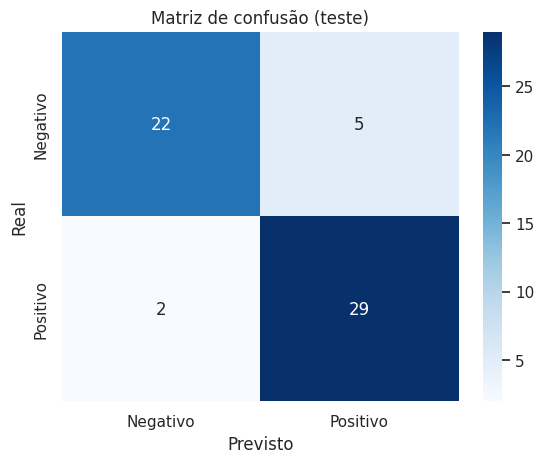

In [17]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negativo", "Positivo"],
            yticklabels=["Negativo", "Positivo"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão (teste)")
plt.show()

## 10. Abrindo a caixa-preta: quais palavras o modelo usa?

Na Regressão Logística, cada palavra tem um **coeficiente**:
- positivo → empurra para "positivo"
- negativo → empurra para "negativo"

Isso permite **auditar** se o modelo aprendeu algo sensato ou se está se apoiando em palavras suspeitas.

Palavras com peso diferente de zero: 129 de 129


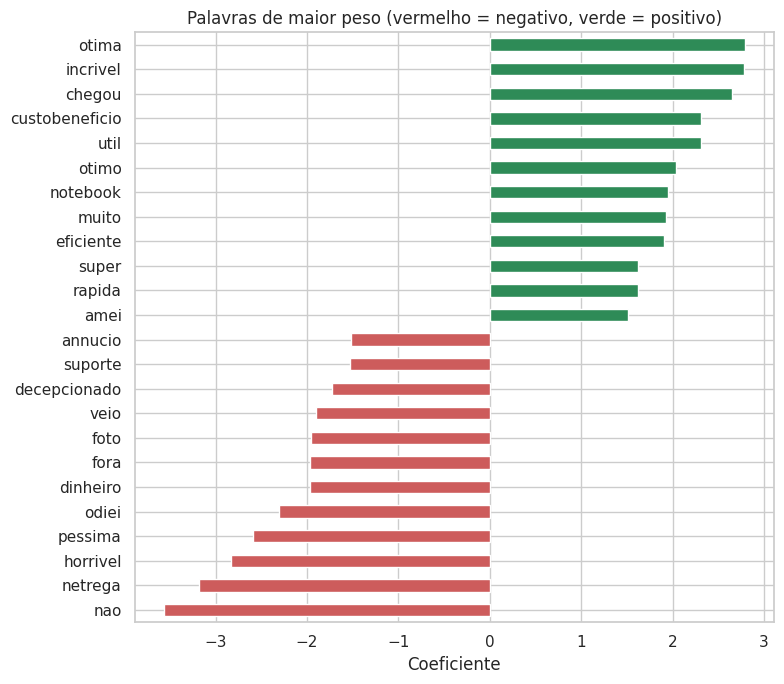

In [18]:
vec = best_model.named_steps["tfidf"]
clf = best_model.named_steps["clf"]

coefs = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())
coefs = coefs[coefs != 0].sort_values()      # l1 zera vários coeficientes
print(f"Palavras com peso diferente de zero: {len(coefs)} de {len(vec.get_feature_names_out())}")

n = min(12, len(coefs) // 2)
extremos = pd.concat([coefs.head(n), coefs.tail(n)])

plt.figure(figsize=(8, 7))
cores = ["indianred" if v < 0 else "seagreen" for v in extremos.values]
extremos.plot.barh(color=cores)
plt.title("Palavras de maior peso (vermelho = negativo, verde = positivo)")
plt.xlabel("Coeficiente")
plt.tight_layout()
plt.show()

## 11. Análise de erros

Métricas dizem **quanto** erra. Olhar os exemplos errados diz **por quê**.
Procure padrões: negações? ironia? rótulos duvidosos?

In [19]:
erros = pd.DataFrame({
    "texto": X_test.values,
    "real": y_test.map({0: "negativo", 1: "positivo"}).values,
    "previsto": pd.Series(y_pred).map({0: "negativo", 1: "positivo"}).values,
    "prob_positivo": best_model.predict_proba(X_test)[:, 1].round(2),
})
erros = erros[erros["real"] != erros["previsto"]]
print(f"{len(erros)} erros em {len(X_test)} exemplos")
pd.set_option("display.max_colwidth", 100)
erros.head(15)

7 erros em 58 exemplos


,texto,real,previsto,prob_positivo
29,a embalagem do mouse chegou um pouco amassada mas o produto esta intacto,negativo,positivo,0.91
31,estou muito impressionado com a compra o celular e incrivel e chegou pontual,negativo,positivo,0.96
36,nao rceomendo a entrega atrasou muito e o monitor nao e como na foto,positivo,negativo,0.07
43,recebi o teclado hoje vou comecar a usar para ver se e bom,negativo,positivo,0.87
47,a cor do teclado e um pouco dfierente do que eu esperava mas tudo bem,positivo,negativo,0.48
51,estou muito feliz com a compra o fone de ouvido e incrivel e chegou no prazo,negativo,positivo,0.97
53,o celular e exatamente como descrito no anuncio faz o que promete,negativo,positivo,0.72


## 12. Salvando e usando o modelo

O pipeline inteiro (TF-IDF + classificador) é salvo, então a entrada pode ser texto cru.
A função agora devolve também a **probabilidade**, útil para marcar casos incertos.

In [ ]:
joblib.dump(best_model, "feedbackModelV2.joblib")
model_deploy = joblib.load("feedbackModelV2.joblib")

def prever_sentimento(reviews, limiar_incerteza=0.6):
    # A limpeza precisa ser a MESMA do treino
    limpos = [clear_text(r) for r in reviews]
    probs = model_deploy.predict_proba(limpos)[:, 1]

    for review, p in zip(reviews, probs):
        classe = "Positivo" if p >= 0.5 else "Negativo"
        confianca = max(p, 1 - p)
        aviso = "  [incerto, revisar manualmente]" if confianca < limiar_incerteza else ""
        print(f"Review: {review!r}")
        print(f"  -> {classe} (confiança {confianca:.0%}){aviso}\n")

novas_reviews = [
    "A bateria do celular não dura nada, péssima compra.",
    "Chegou antes do prazo e o produto é de ótima qualidade! Estou muito feliz.",
    "O serviço de atendimento foi rápido e eficiente.",
    "Não recomendo, veio faltando peças e a cor estava errada.",
    "Não gostei, esperava muito mais.",
    "Gostei bastante, recomendo.",
]
prever_sentimento(novas_reviews)

## 13. Conclusões e lições

1. **Higiene de dados vem antes do modelo.** Deduplicar e remover conflitos mudou o que a métrica significa; resultados antes e depois **não são diretamente comparáveis**, e o novo é o mais honesto.
2. **Sempre tenha um baseline.** Sem ele, "80% de acurácia" não diz nada.
3. **Valide mudanças com CV, não com intuição.** O scaler, os bigramas e a troca de modelo foram decididos por dados.
4. **Com poucos dados, a variância domina.** Olhe o desvio-padrão da CV antes de declarar um vencedor.
5. **Inspecione coeficientes e erros.** É assim que se descobre se o modelo aprendeu "sentimento" ou apenas "palavras do dataset".
6. **Pré-processamento deve ser idêntico no treino e na produção.** Por isso `clear_text` é aplicada na função de predição.

### Próximos passos sugeridos
- Coletar **mais dados reais** e revisar os rótulos manualmente
- Testar embeddings de sentenças ou um modelo em português como o **BERTimbau**
- Calibrar probabilidades (`CalibratedClassifierCV`) se for usar o limiar de incerteza em produção
- Criar um conjunto de teste escrito à mão, com negações, ironia e frases curtas